# 1. Quanto os imóveis valorizaram de verdade?

"Imóvel nunca perde valor" é a frase que mais se ouve em qualquer conversa sobre comprar ou alugar.
Este notebook confere essa afirmação com dados, e a resposta depende de uma palavra: **inflação**.

**Fontes**

- **Índice FipeZAP** (Fipe): preço médio do m² de apartamentos prontos em 56 cidades, mensal, desde 2008.
- **IPCA** (IBGE): para transformar preços de cada época em reais de hoje.
- **IVG-R** (Banco Central): índice calculado a partir do valor de avaliação dos imóveis dados em garantia de
  financiamentos. Serve de contraprova para o FipeZAP.

**Dois cuidados antes de começar**

1. O FipeZAP mede **preço de anúncio**, não o preço em que o negócio foi fechado. Em mercado fraco o desconto
   entre um e outro cresce, e o índice demora a mostrar a queda.
2. O índice cobre **apartamentos prontos**. Casas e imóveis na planta ficam de fora.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from comprar_ou_alugar import estilo
from comprar_ou_alugar.caminhos import TRATADOS
from comprar_ou_alugar.estilo import br, pct
from comprar_ou_alugar.fontes.fipezap import NACIONAL

estilo.aplicar()

cidades = pd.read_parquet(TRATADOS / "cidades.parquet")
mensal = pd.read_parquet(TRATADOS / "mensal.parquet").set_index("data")

TRES_CIDADES = ["São Paulo", "Rio de Janeiro", "Belo Horizonte"]

A tabela `cidades` tem uma linha por mês, cidade e número de dormitórios. As colunas `_real` são os mesmos
preços corrigidos pelo IPCA até o último mês com inflação divulgada.

In [2]:
total = cidades[cidades["quartos"] == "total"]
nominal = total.pivot(index="data", columns="cidade", values="venda_preco_m2")
real = total.pivot(index="data", columns="cidade", values="venda_preco_m2_real")

ultimo = real[NACIONAL].last_valid_index()
print(f"Preços reais em R$ de {ultimo:%m/%Y}. Cidades: {real.shape[1] - 1}.")
total[total["cidade"] == "São Paulo"].tail(3)

Preços reais em R$ de 08/2026. Cidades: 56.


,data,cidade,uf,quartos,venda_indice,venda_preco_m2,aluguel_indice,aluguel_preco_m2,rentabilidade_aluguel_mes,venda_preco_m2_real,aluguel_preco_m2_real
18254,2026-07-01,São Paulo,SP,total,285.469048,12098.856016,248.491203,65.177167,0.005354,12060.147159,64.968640
18255,2026-08-01,São Paulo,SP,total,286.515255,12143.196742,249.201855,65.363565,0.005350,12143.196742,65.363565
18256,2026-09-01,São Paulo,SP,total,287.997688,12206.025761,NaN,NaN,NaN,NaN,NaN


## O preço nominal engana

No índice nacional, o m² anunciado mais que quadruplicou desde 2008. Descontada a inflação, a história é outra:
os preços subiram forte até 2014, caíram por oito anos seguidos e ainda não voltaram ao pico.

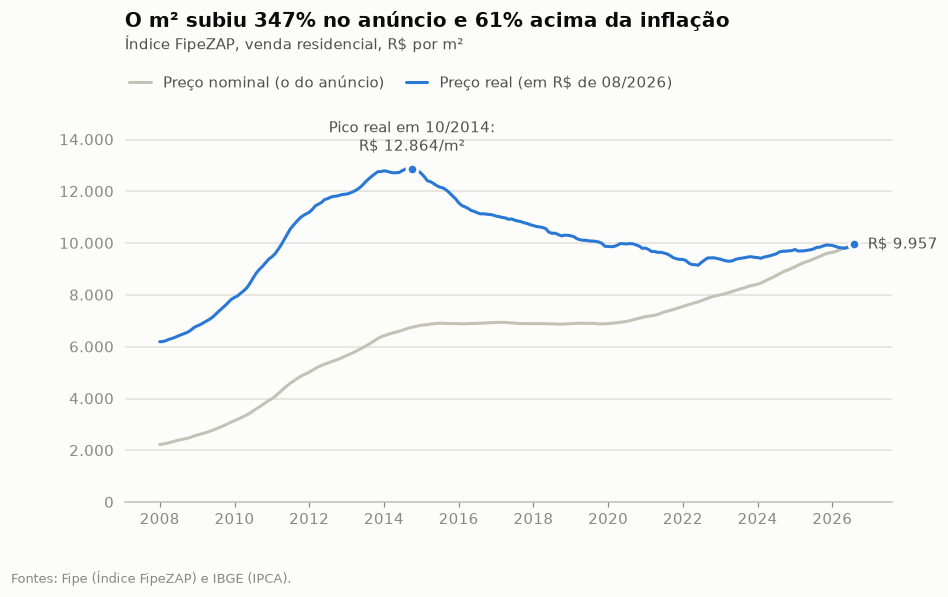

In [3]:
fig, ax = plt.subplots()
ax.plot(nominal[NACIONAL], color=estilo.CINZA, label="Preço nominal (o do anúncio)")
ax.plot(real[NACIONAL], color=estilo.AZUL, label=f"Preço real (em R$ de {ultimo:%m/%Y})")

alta_nominal = nominal[NACIONAL][ultimo] / nominal[NACIONAL].dropna().iloc[0] - 1
alta_real = real[NACIONAL][ultimo] / real[NACIONAL].dropna().iloc[0] - 1
estilo.titulo(
    ax,
    f"O m² subiu {pct(alta_nominal)} no anúncio e {pct(alta_real)} acima da inflação",
    "Índice FipeZAP, venda residencial, R$ por m²",
    legenda=True,
)
estilo.eixo_br(ax.yaxis)
ax.set_ylim(0)

pico = real[NACIONAL].idxmax()
ax.annotate(
    f"Pico real em {pico:%m/%Y}:\nR$ {br(real[NACIONAL][pico])}/m²",
    (pico, real[NACIONAL][pico]),
    xytext=(0, 12),
    textcoords="offset points",
    ha="center",
    fontsize=9.5,
    color=estilo.TINTA_SECUNDARIA,
)
ax.plot(pico, real[NACIONAL][pico], "o", ms=7, color=estilo.AZUL, mec=estilo.SUPERFICIE, mew=2)
ax.set_ylim(0, real[NACIONAL].max() * 1.22)
estilo.rotular_fins(ax, lambda v: f"R$ {br(v)}", so=[f"Preço real (em R$ de {ultimo:%m/%Y})"])
estilo.fonte(fig, "Fontes: Fipe (Índice FipeZAP) e IBGE (IPCA).")
plt.show()

In [4]:
resumo = []
for cidade in [NACIONAL, *TRES_CIDADES]:
    r, n = real[cidade].dropna(), nominal[cidade].dropna()
    pico = r.idxmax()
    resumo.append(
        {
            "cidade": cidade,
            "série desde": f"{r.index[0]:%m/%Y}",
            "alta nominal": pct(n[ultimo] / n.iloc[0] - 1),
            "alta real": pct(r[ultimo] / r.iloc[0] - 1),
            "pico real": f"{pico:%m/%Y}",
            "hoje × pico": pct(r[ultimo] / r[pico] - 1),
            "10 anos (real)": pct(r[ultimo] / r[ultimo - pd.DateOffset(years=10)] - 1, sinal=True),
            "5 anos (real)": pct(r[ultimo] / r[ultimo - pd.DateOffset(years=5)] - 1, sinal=True),
        }
    )
pd.DataFrame(resumo).set_index("cidade")

,série desde,alta nominal,alta real,pico real,hoje × pico,10 anos (real),5 anos (real)
cidade,,,,,,,
Índice FipeZAP,01/2008,347%,61%,10/2014,−23%,−11%,+4%
São Paulo,01/2008,365%,67%,08/2014,−23%,−11%,−3%
Rio de Janeiro,01/2008,283%,38%,08/2014,−45%,−33%,−10%
Belo Horizonte,04/2009,251%,35%,11/2014,−9%,+4%,+15%


## Três cidades, três histórias

- **Rio de Janeiro** viveu o ciclo mais extremo: chegou a ter o m² mais caro do país em 2014 (Copa, Olimpíada,
  petróleo) e desde então perdeu quase metade do valor real. Ainda está perto do fundo.
- **São Paulo** caiu menos, mas quem comprou no pico de 2014 também está cerca de um quinto abaixo em termos reais.
- **Belo Horizonte** é a que mais se recuperou: voltou a subir a partir de 2022 e está perto do pico.

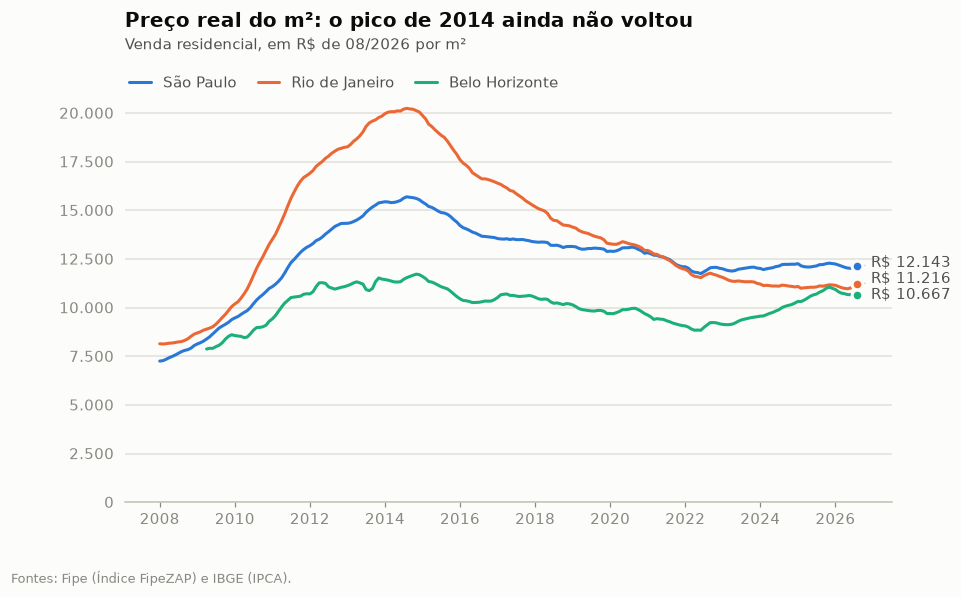

In [5]:
fig, ax = plt.subplots()
for cidade in TRES_CIDADES:
    ax.plot(real[cidade], color=estilo.CORES_CIDADES[cidade], label=cidade)

estilo.titulo(
    ax,
    "Preço real do m²: o pico de 2014 ainda não voltou",
    f"Venda residencial, em R$ de {ultimo:%m/%Y} por m²",
    legenda=True,
)
estilo.eixo_br(ax.yaxis)
ax.set_ylim(0)
estilo.rotular_fins(ax, lambda v: f"R$ {br(v)}")
estilo.fonte(fig, "Fontes: Fipe (Índice FipeZAP) e IBGE (IPCA).")
plt.show()

## E no resto do país?

O FipeZAP foi incorporando cidades aos poucos; 25 delas têm pelo menos dez anos de série. Em dez anos, a maioria
**perdeu** para a inflação. As exceções são um grupo pequeno, puxado pelo Espírito Santo, por Santa Catarina,
Goiânia e Curitiba.

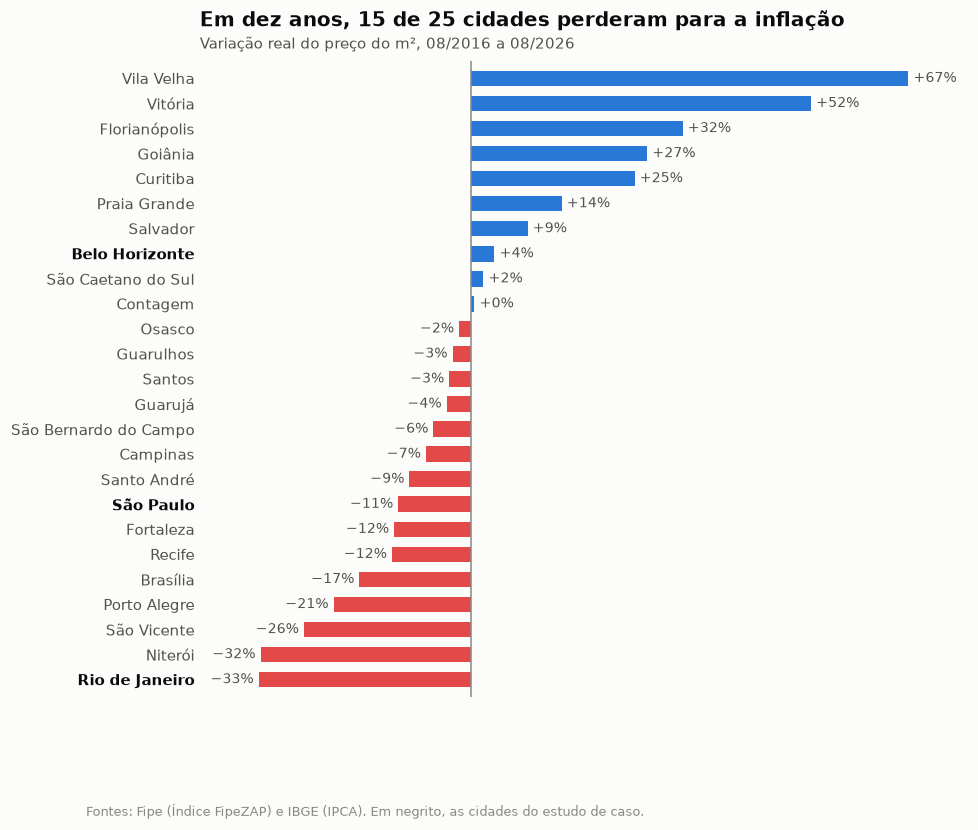

In [6]:
dez_anos = (real.loc[ultimo] / real.loc[ultimo - pd.DateOffset(years=10)] - 1).drop(NACIONAL).dropna().sort_values()
perderam = (dez_anos < 0).sum()

fig, ax = plt.subplots(figsize=(9, 7.5))
cores = [estilo.VERMELHO if v < 0 else estilo.AZUL for v in dez_anos]
ax.barh(dez_anos.index, dez_anos, color=cores, height=0.62)
for posicao, (cidade, valor) in enumerate(dez_anos.items()):
    ax.text(
        valor + (0.008 if valor >= 0 else -0.008),
        posicao,
        pct(valor, sinal=True),
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=9,
        color=estilo.TINTA_SECUNDARIA,
    )

estilo.titulo(
    ax,
    f"Em dez anos, {perderam} de {len(dez_anos)} cidades perderam para a inflação",
    f"Variação real do preço do m², {ultimo - pd.DateOffset(years=10):%m/%Y} a {ultimo:%m/%Y}",
)
ax.grid(False)
ax.axvline(0, color=estilo.TINTA_SUAVE, lw=1)
ax.spines["bottom"].set_visible(False)
ax.set_xticks([])
ax.set_xlim(dez_anos.min() - 0.09, dez_anos.max() + 0.09)
ax.margins(y=0.015)
ax.tick_params(axis="y", length=0, labelcolor=estilo.TINTA_SECUNDARIA)
for rotulo in ax.get_yticklabels():
    if rotulo.get_text() in TRES_CIDADES:
        rotulo.set_fontweight("bold")
        rotulo.set_color(estilo.TINTA)
estilo.fonte(fig, "Fontes: Fipe (Índice FipeZAP) e IBGE (IPCA). Em negrito, as cidades do estudo de caso.")
plt.show()

## Contraprova: o índice do Banco Central

Como o FipeZAP mede anúncios, vale comparar com uma fonte de natureza diferente. O **IVG-R** usa o valor pelo
qual os bancos avaliam os imóveis dados em garantia de financiamentos, em 11 regiões metropolitanas.

Os dois contam a mesma história: alta forte até 2014, queda real longa depois. O IVG-R mostra uma alta total
menor, o que é coerente com a ideia de que o preço de anúncio é mais otimista que o de avaliação.

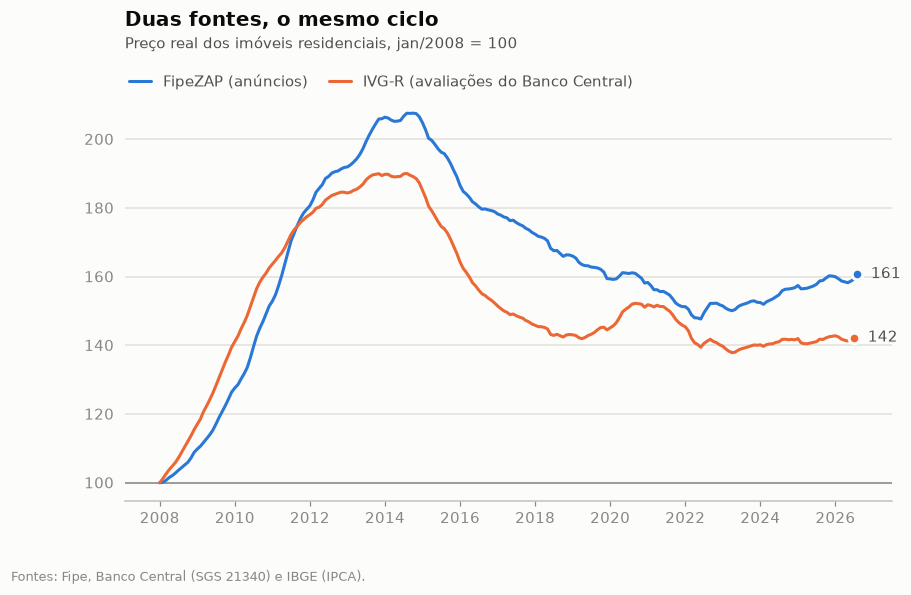

Alta real acumulada desde jan/2008:
  FipeZAP (anúncios): +61% até 08/2026
  IVG-R (avaliações do Banco Central): +42% até 07/2026


In [7]:
ivgr_real = (mensal["ivgr"] / mensal["ipca_indice"]).dropna()
base = pd.Timestamp("2008-01-01")
comparacao = pd.DataFrame(
    {
        "FipeZAP (anúncios)": real[NACIONAL] / real[NACIONAL][base] * 100,
        "IVG-R (avaliações do Banco Central)": ivgr_real / ivgr_real[base] * 100,
    }
).loc[base:]

fig, ax = plt.subplots()
ax.plot(comparacao["FipeZAP (anúncios)"], color=estilo.AZUL, label="FipeZAP (anúncios)")
ax.plot(
    comparacao["IVG-R (avaliações do Banco Central)"], color=estilo.LARANJA, label="IVG-R (avaliações do Banco Central)"
)
estilo.titulo(ax, "Duas fontes, o mesmo ciclo", "Preço real dos imóveis residenciais, jan/2008 = 100", legenda=True)
estilo.linha_de_base(ax, 100)
estilo.rotular_fins(ax, lambda v: br(v))
estilo.fonte(fig, "Fontes: Fipe, Banco Central (SGS 21340) e IBGE (IPCA).")
plt.show()

print("Alta real acumulada desde jan/2008:")
for nome, serie in comparacao.items():
    fim = serie.dropna()
    print(f"  {nome}: {pct(fim.iloc[-1] / 100 - 1, sinal=True)} até {fim.index[-1]:%m/%Y}")

## O que fica deste notebook

1. **Em reais de hoje, o imóvel brasileiro vale menos do que em 2014.** O índice nacional está cerca de 23% abaixo
   do pico real; o Rio, 45%; São Paulo, 23%; Belo Horizonte, 9%.
2. **O preço nominal quase nunca cai**, e é por isso que a perda passa despercebida: o anúncio continua subindo,
   só que menos que a inflação.
3. **O ponto de partida importa muito.** Quem comprou em 2008 ganhou da inflação com folga (o m² real subiu 61%
   no índice nacional); quem comprou em 2014 ainda está no prejuízo real, 12 anos depois.
4. **A valorização é só metade do retorno de um imóvel.** A outra metade é o aluguel que ele rende (ou que o dono
   deixa de pagar). É o assunto do próximo notebook.